In [2]:
from qiskit import *
from qiskit.visualization import plot_histogram
%matplotlib inline

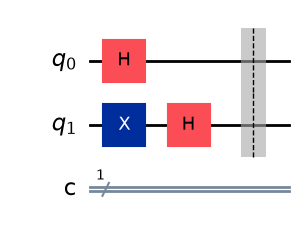

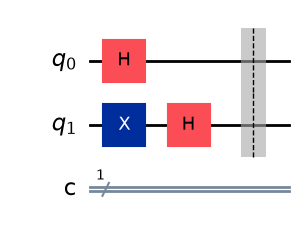

In [4]:
circuit = QuantumCircuit(2,1)
circuit.h(0)
circuit.x(1)
circuit.h(1)
circuit.barrier()
circuit.draw(output = 'mpl')

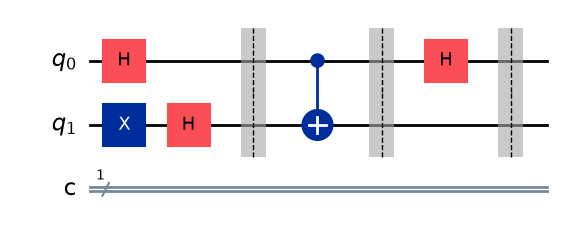

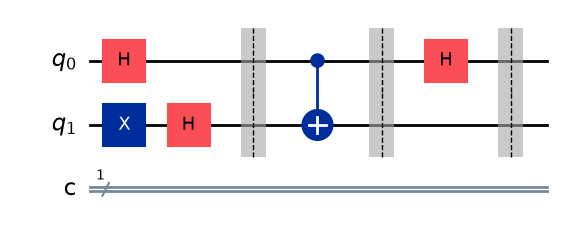

In [6]:
circuit.cx(0,1)
circuit.barrier()
circuit.h(0)
circuit.barrier()
circuit.draw(output = 'mpl')

In [7]:
circuit.measure(0,0)

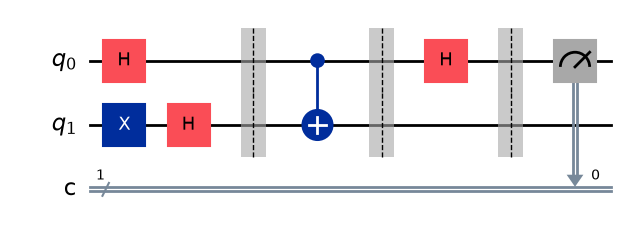

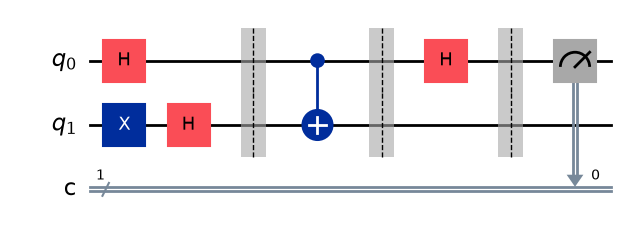

In [8]:
circuit.draw(output = 'mpl')

In [9]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
simulator = AerSimulator()

job = simulator.run(circuit, shots=1024)

result = job.result()

counts = result.get_counts()

print(counts)

{'1': 1024}


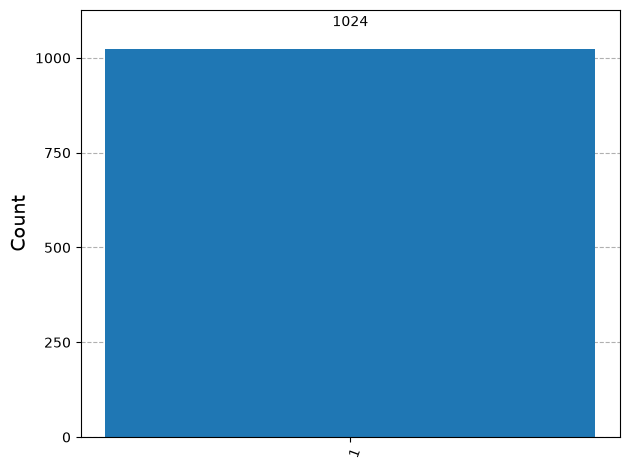

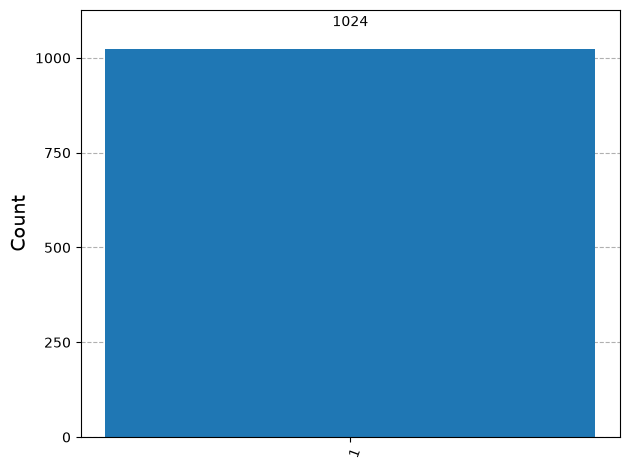

In [11]:
plot_histogram(counts)

In [12]:
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService()
backends = service.backends()
for backend in backends:
    print(backend.name)
for backend in service.backends():
    status = backend.status()

    print("Backend:", backend.name)
    print("Operational:", status.operational)
    print("Pending jobs:", status.pending_jobs)



qiskit_runtime_service.__init__:WARNING:2026-10-30 15:52:53,968: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-30 15:52:53,969: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-30 15:52:56,065: Loading instance: open-instance, plan: open


ibm_fez
ibm_kingston
ibm_marrakesh
Backend: ibm_fez
Operational: True
Pending jobs: 0
Backend: ibm_kingston
Operational: True
Pending jobs: 289
Backend: ibm_marrakesh
Operational: True
Pending jobs: 1


In [13]:
quantum_computer = service.backend("ibm_fez")
from qiskit import transpile
compiled_circuit = transpile(
    circuit,
    backend=quantum_computer,
    translation_method="translator"
)
from qiskit_ibm_runtime import SamplerV2 as Sampler
sampler = Sampler(mode=quantum_computer)
job = sampler.run([compiled_circuit], shots=1024)
print("Job ID:", job.job_id())
print("Status:", job.status())

qiskit_runtime_service.backends:WARNING:2026-10-30 15:54:09,788: Using instance: open-instance, plan: open
/var/folders/kf/jd5w__vs3kg4vxwlhcczgzsm0000gn/T/ipykernel_40182/3686002206.py:9: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=quantum_computer)


Job ID: dbi70j81h92s7382tc00
Status: QUEUED


In [14]:
print("Status:", job.status())

Status: DONE


In [15]:
result = job.result()

counts = result[0].data.c.get_counts()

print(counts)

{'1': 979, '0': 45}


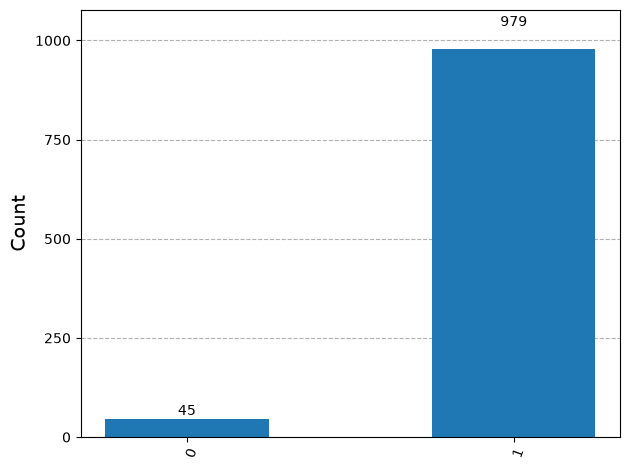

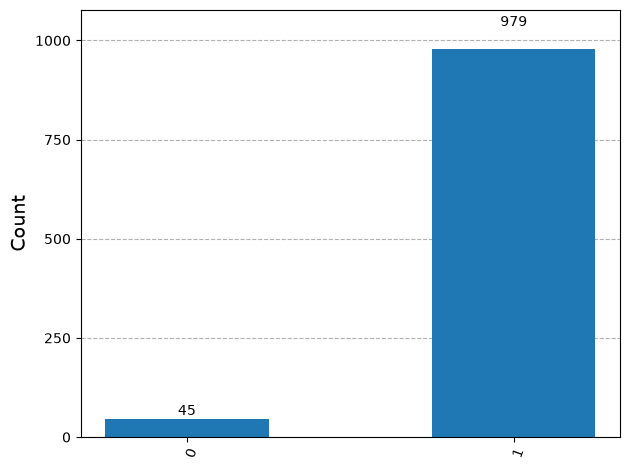

In [16]:
plot_histogram(counts)